### Expected value of the worst case completion time over all possibilities of failure


In [6]:

import itertools
import math
from functools import lru_cache
import matplotlib.pyplot as plt

import numpy as np
import sys

from shared import *
from pathlib import Path


#### Lower-bound (benchmark) method (algorithm A):
E[Completion time] = Σ P(F = f) × W_A(f)


W_A(f): the most rounds A can take when exactly f workers fail in total, over every choice of
        WHICH workers fail and in WHICH round (exhaustive search).

P(F = f): the chance that a real run of A has f failures in total (over the whole run).

Expected worst case = sum over f of P(F = f) * W_A(f).  This is >= A's expected time E[T].


In [7]:

def finished_partitions(r, a, failed):
    """Partitions finished this round when the workers in `failed` (indices) fail.

    >>> finished_partitions(3, 5, {0, 1})     # groups [2, 2, 1]: both workers of partition 0 fail
    2
    """
    groups = round_robin_groups(r, a)
    partition_of_worker = [g for g, size in enumerate(groups) for _ in range(size)]
    return len({partition_of_worker[i] for i in range(a) if i not in failed})


def A_worst_rounds(N, k, f):
    """Most rounds A can take with exactly f failures, over every 'which' and 'when'.

    >>> A_worst_rounds(12, 6, 2)
    3
    >>> A_worst_rounds(8, 5, 1)       # worse than ceil(8/4) = 2: the failure comes in round 2
    3
    """
    @lru_cache(maxsize=None)
    def W(r, a, f_left):
        if r == 0:
            return 0
        if a == 1:
            return r                                   # last worker can't fail
        worst_next = 0
        for x in range(min(f_left, a - 1) + 1):        # how many fail this round
            for failed in itertools.combinations(range(a), x):   # which ones
                done = finished_partitions(r, a, set(failed))
                worst_next = max(worst_next, W(r - done, a - x, f_left - x))
        return 1 + worst_next
    return W(N, k, f)


def A_failure_count_distribution(N, k, P):
    """P(F = f): chance of f failures in total over a whole run of A, as {f: probability}.

    >>> d = A_failure_count_distribution(5, 2, 0.1)
    >>> round(d[0], 4), round(d[1], 4)
    (0.5314, 0.4686)
    """
    @lru_cache(maxsize=None)
    def D(r, a):
        if r == 0 or a == 1:
            return {0: 1.0}                            # no more failures possible
        dist = {}
        for failed, p in failure_sets(a, P):           # every outcome of THIS round
            failed_idx = {i for i in range(a) if failed[i]}
            done = finished_partitions(r, a, failed_idx)
            for more, q in D(r - done, a - len(failed_idx)).items():   # later rounds
                f = len(failed_idx) + more
                dist[f] = dist.get(f, 0) + p * q
        return dist
    return D(N, k)


def A_expected_worst_rounds(N, k, P):
    """Expected worst case: sum over f of P(F = f) * W_A(f).

    >>> round(A_expected_worst_rounds(12, 6, 0.1), 4)
    3.1853
    """
    dist = A_failure_count_distribution(N, k, P)
    return sum(p * A_worst_rounds(N, k, f) for f, p in dist.items())


if __name__ == "__main__":
    trial_cases = [(5, 2, 0.1), (5, 3, 0.1), (5, 3, 0.3), (9, 3, 0.1), (15, 3, 0.3), (12, 4, 0.2), (12, 6, 0.1)]
    header = f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | {'Worst Case':>14} (T)|"
    print(header)
    print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")
    for N, k, P in trial_cases:
        print(f"| {N:>12} | {k:>9} | {P:>4} | "
              f"{A_timed_worst(N, k, P):>14.4f} |")


| N partitions | k workers |    P |     Worst Case (T)|
|--------------|-----------|------|-------------------|
|            5 |         2 |  0.1 |         3.5339 |
|            5 |         3 |  0.1 |         2.5707 |
|            5 |         3 |  0.3 |         3.5393 |
|            9 |         3 |  0.1 |         4.4099 |
|           15 |         3 |  0.3 |        12.6767 |
|           12 |         4 |  0.2 |         6.5490 |
|           12 |         6 |  0.1 |         2.9457 |


#### Worst-case completion time of method B (two pointer).

Implementation:

State of a run: which partitions are done, and which workers are alive. Both are stored as
bitmasks: bit p-1 of `done` is set when partition p is done; bit w of `alive` when worker w is alive.
Each round, every live worker takes the first partition on its list that isn't done.
Fast up to at least 16 partitions and 8 workers (about 1 second); the search grows quickly beyond that.


In [8]:
# Worst-case completion time of method B (two pointer), and its expected value.

# W_B(f): the most rounds B can take when exactly f workers fail in total, over every choice of
#         WHICH workers fail and in WHICH round (exhaustive search).
# P(F = f): the chance that a real run of B has f failures in total (over the whole run).
# Expected worst case = sum over f of P(F = f) * W_B(f).  This is >= B's expected time E[T].

# State of a run: which partitions are done, and which workers are alive. Both are stored as
# bitmasks: bit p-1 of `done` is set when partition p is done; bit w of `alive` when worker w is alive.
# Each round, every live worker takes the first partition on its list that isn't done.
# Fast up to at least 16 partitions and 8 workers (about 1 second); the search grows quickly beyond that.


def B_failure_count_distribution(schedules, N, P):
    """P(F = f): chance of f failures in total over a whole run of B, as {f: probability}.

    >>> d = B_failure_count_distribution(pair_schedules(5, 2), 5, 0.1)
    >>> round(d[0], 4), round(d[1], 4)
    (0.5314, 0.4686)
    """
    k = len(schedules)
    all_done = (1 << N) - 1

    @lru_cache(maxsize=None)
    def D(done, alive):
        live = [w for w in range(k) if alive >> w & 1]
        if done == all_done or len(live) == 1:
            return {0: 1.0}                                       # no more failures possible
        targets = targets_this_round(schedules, done, live)
        dist = {}
        for failed, p in failure_sets(len(live), P):               # every outcome of THIS round
            new_done, new_alive = done, alive
            for i, w in enumerate(live):
                if failed[i]:
                    new_alive &= ~(1 << w)
                else:
                    new_done |= 1 << (targets[i] - 1)
            for more, q in D(new_done, new_alive).items():         # later rounds
                f = sum(failed) + more
                dist[f] = dist.get(f, 0) + p * q
        return dist

    return D(0, (1 << k) - 1)


def B_expected_worst_rounds(N, k, P):
    """Expected worst case for B: sum over f of P(F = f) * W_B(f).

    >>> round(B_expected_worst_rounds(5, 2, 0.1), 4)     # same as method A for 2 workers
    3.9371
    """
    schedules = pair_schedules(N, k)
    dist = B_failure_count_distribution(schedules, N, P)
    return sum(p * B_worst_rounds(schedules, N, f) for f, p in dist.items())


if __name__ == "__main__":
    trial_cases = [(5, 2, 0.1), (8, 2, 0.1), (8, 4, 0.1), (8, 4, 0.3), (12, 4, 0.2), (12, 6, 0.1), (12, 6, 0.3)]

    header = f"| {'N partitions':>12} | {'k workers':>9} | {'P':>4} | {'B expected worst':>16} |"
    print(header)
    print("|" + "|".join("-" * len(col) for col in header.split("|")[1:-1]) + "|")
    for N, k, P in trial_cases:
        worst = B_timed_worst(pair_schedules(N, k), N, P)
        print(f"| {N:>12} | {k:>9} | {P:>4} | {worst:>16.4f} |")

    # W_B(f) for each number of failures
    for N, k in [(8, 4), (12, 6)]:
        S = pair_schedules(N, k)
        print(f"N={N}, k={k}: W_B(f) =", {f: B_worst_rounds(S, N, f) for f in range(k)})

| N partitions | k workers |    P | B expected worst |
|--------------|-----------|------|------------------|
|            5 |         2 |  0.1 |           3.5339 |
|            8 |         2 |  0.1 |           5.5720 |
|            8 |         4 |  0.1 |           2.8627 |
|            8 |         4 |  0.3 |           4.9011 |
|           12 |         4 |  0.2 |           6.6782 |
|           12 |         6 |  0.1 |           3.2221 |
|           12 |         6 |  0.3 |           6.4874 |
N=8, k=4: W_B(f) = {0: 2, 1: 3, 2: 4, 3: 8}
N=12, k=6: W_B(f) = {0: 2, 1: 3, 2: 4, 3: 5, 4: 8, 5: 12}


### Graphs of worst case for either increasing partitions, or increasing worker nodes
Both values are exact (no simulation)

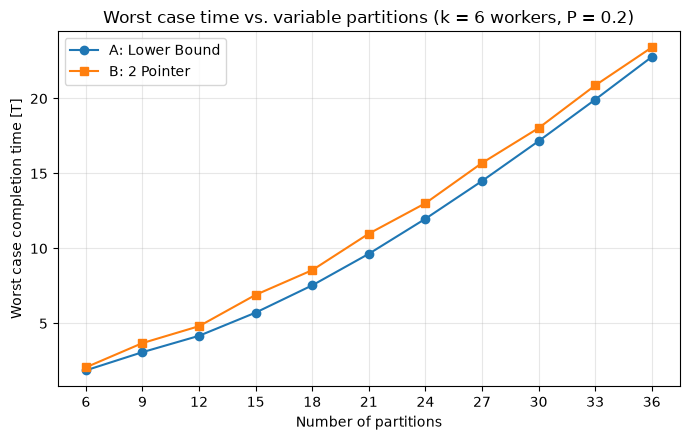

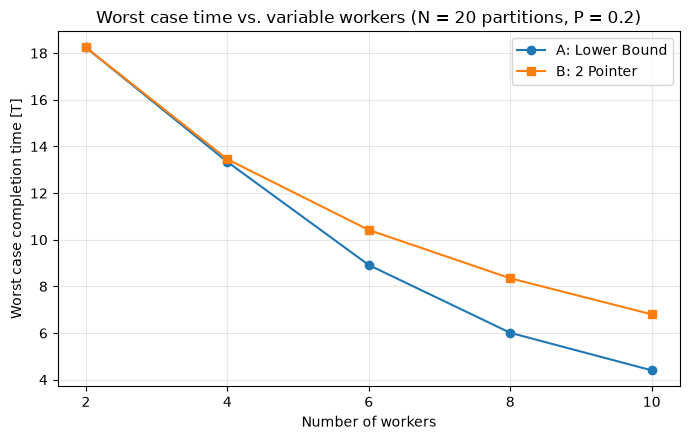

In [9]:
# Expected worst-case completion time vs. number of partitions, and vs. number of workers,
# for method A (lower bound, full monitoring) and method B (2 potiner, done flags only).
# Both values are exact (no simulation), so there are no error bars.
# Needs A_worst_case.py, B_worst_case.py, utils.py, pair_schedules.py and
# lower_bound_expected_time.py in the same folder.

# The exact worst-case search for B grows quickly, so the sizes are smaller than in the
# expected-time graphs: about 15 s for graph 1 and 25 s for graph 2.

P = 0.2            # failure probability per worker per round


def plot_comparison(x_values, A_values, B_values, xlabel, title, filename):
    plt.figure(figsize=(7, 4.5))
    plt.plot(x_values, A_values, "o-", label="A: Lower Bound")
    plt.plot(x_values, B_values, "s-", label="B: 2 Pointer")
    plt.xticks(x_values)                       # whole-number ticks at the values tested
    plt.xlabel(xlabel)
    plt.ylabel("Worst case completion time [T]")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(Path("images")/filename, dpi=150)
    plt.show()


# ---------- Graph 1: increasing partitions, k = 6 workers ----------
k = 6
N_values = list(range(6, 37, 3))

A_values, B_values = [], []
for N in N_values:
    A_values.append(A_timed_worst(N, k, P))
    B_values.append(B_timed_worst(pair_schedules(N, k), N, P))

plot_comparison(N_values, A_values, B_values,
                xlabel="Number of partitions",
                title=f"Worst case time vs. variable partitions (k = {k} workers, P = {P})",
                filename="c_worst_increasing_partitions.png")


# ---------- Graph 2: increasing workers, N = 20 partitions ----------
N = 20
k_values = list(range(2, 11, 2))          # pair schedules need an even number of workers

A_values, B_values = [], []
for k in k_values:
    A_values.append(A_timed_worst(N, k, P))
    B_values.append(B_timed_worst(pair_schedules(N, k), N, P))

plot_comparison(k_values, A_values, B_values,
                xlabel="Number of workers",
                title=f"Worst case time vs. variable workers (N = {N} partitions, P = {P})",
                filename="c_worst_increasing_workers.png")